In [273]:
# . Get data from 2020-01-01 to 2022-01-01 for tickers AAPL, WMT, TSLA, KO, BAC, T, META, NFLX, CRM.
# a. Create the following portfolios:
# i. Markovitz Portfolio
# ii. Global Minimum Variance Portfolio
# iii. Equally weighted portfolio
# iv. Naïve risk parity portfolio (inverse volatility portfolio)
# v. Vanilla risk parity portfolio (solving risk budgeting equations)


# b. Do the following for each of the portfolios defined above and comment the results:
# • Compute and bar plot each asset’s allocations.
# • Compute the annualized returns, st dev and Sharpe ratio and plot the cumulative returns.
# • Plot the drawdown.
# • Compute and bar plot the risk contribution.


In [47]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import seaborn as sns

In [48]:
tickers = ["AAPL", "WMT", "TSLA", "KO", "BAC", "T", "META", "NFLX", "CRM"]

df = yf.download(
    tickers,
    start="2020-01-01",
    end="2022-01-01",
    progress=False,
    group_by='ticker',  
    auto_adjust=False
)
if isinstance(df.columns, pd.MultiIndex):
    df = df.xs('Adj Close', level=1, axis=1)
else:
    df = df.filter(like='Adj Close')  

In [49]:
rf = 0.05 #Assume rf is 5%

In [50]:
log_returns = np.log(df / df.shift(1)).dropna()
log_returns

Ticker,NFLX,META,TSLA,AAPL,BAC,KO,WMT,T,CRM
Date,,,,,,,,,
2020-01-03,-0.011926,-0.005305,0.029203,-0.009770,-0.020982,-0.005471,-0.008867,0.005134,-0.004923
2020-01-06,0.030014,0.018659,0.019072,0.007937,-0.001434,-0.000366,-0.002038,0.001023,0.042878
2020-01-07,-0.015242,0.002161,0.038067,-0.004714,-0.006621,-0.007712,-0.009308,0.003829,0.014595
2020-01-08,0.025404,0.010087,0.048033,0.015958,0.010059,0.001841,-0.003437,0.003053,0.007528
2020-01-09,-0.010668,0.014209,-0.022189,0.021018,0.001714,0.018051,0.010277,0.003058,0.012720
...,...,...,...,...,...,...,...,...,...
2021-12-27,-0.001581,0.032112,0.024935,0.022715,0.004940,0.007359,0.009064,-0.003625,0.020179
2021-12-28,-0.003938,0.000116,-0.005013,-0.005784,0.001343,0.003914,0.014249,0.001613,-0.011095
2021-12-29,-0.000278,-0.009519,-0.002097,0.000502,-0.001567,0.001188,-0.000490,-0.007279,-0.003569


In [51]:
avg_returns = log_returns.mean()
cov_matrix = log_returns.cov()
std = log_returns.std()

In [52]:
def portfolio_return(weights, avg_returns):
    return np.dot(weights, avg_returns) * 252

In [53]:
def portfolio_volatility(weights, cov_matrix):
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix,weights))) * np.sqrt(252)

In [54]:
def portfolio_sharpe(weights, avg_returns, cov_matrix,rf):
    ret = portfolio_return(weights, avg_returns)
    vol = portfolio_volatility(weights, cov_matrix)
    return (ret - rf) / vol

In [55]:
#set up constrains

constraints = ({'type':'eq','fun': lambda w:np.sum(w)-1})
bounds = tuple((0, 1) for _ in range(len(tickers)))

In [56]:
weights_df = pd.DataFrame(index=tickers)
weights_df

""
AAPL
WMT
TSLA
KO
BAC
T
META
NFLX
CRM


In [57]:
initial_weights = np.ones(len(tickers)) / len(tickers)

In [58]:
# i. Markovitz Portfolio
from scipy.optimize import minimize
neg_sharpe = lambda w: -portfolio_sharpe(w, avg_returns, cov_matrix, rf)
sharpe_opt = minimize(neg_sharpe, initial_weights, method='SLSQP', bounds=bounds, constraints=constraints)
weights_df['Markovitz'] = sharpe_opt.x
weights_df['Markovitz']

AAPL    0.000000e+00
WMT     0.000000e+00
TSLA    6.907199e-01
KO      3.092801e-01
BAC     7.254505e-17
T       6.272742e-17
META    1.390071e-17
NFLX    1.774882e-16
CRM     0.000000e+00
Name: Markovitz, dtype: float64

In [59]:
# ii. Global Minimum Variance Portfolio
vol_func = lambda w: portfolio_volatility(w, cov_matrix)
gmvp_port = minimize(vol_func, initial_weights, method='SLSQP', bounds=bounds, constraints=constraints)
weights_df['GMVP'] = gmvp_port.x
weights_df['GMVP']

AAPL    1.188958e-01
WMT     1.207348e-02
TSLA    0.000000e+00
KO      7.250602e-18
BAC     0.000000e+00
T       2.728428e-01
META    4.219757e-01
NFLX    1.742123e-01
CRM     1.471804e-17
Name: GMVP, dtype: float64

In [60]:
# iii. Equally Weighted Portfolio (EWP)
weights_df['Equally Weighted'] = initial_weights
weights_df['Equally Weighted']

AAPL    0.111111
WMT     0.111111
TSLA    0.111111
KO      0.111111
BAC     0.111111
T       0.111111
META    0.111111
NFLX    0.111111
CRM     0.111111
Name: Equally Weighted, dtype: float64

In [61]:
# iv. Naïve risk parity portfolio (inverse volatility portfolio)
inv_vol = 1 / std
weights_inv_vol = inv_vol / np.sum(inv_vol) 
weights_df['Naive Risk Parity'] = weights_inv_vol
weights_df['Naive Risk Parity']

AAPL    0.107088
WMT     0.160177
TSLA    0.054074
KO      0.149099
BAC     0.088906
T       0.139790
META    0.103733
NFLX    0.101442
CRM     0.095691
Name: Naive Risk Parity, dtype: float64

In [64]:
# v. Vanilla risk parity portfolio (solving risk budgeting equations)
target_risk_budget = np.array([1/len(tickers)] * len(tickers)) 

In [79]:
def daily_risk_contribution(weights, cov_matrix):
    port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    mrc = np.dot(cov_matrix, weights) / port_vol
    trc = weights * mrc
    return trc, port_vol

In [80]:
def risk_budget_equations(weights, target_risk_budget, cov_matrix):
    weights = np.abs(weights) 
    weights /= np.sum(weights)
    trc, _ = daily_risk_contribution(weights, cov_matrix)
    trc_ratio = trc / np.sum(trc)
    return np.sum((trc_ratio - target_risk_budget) ** 2)

In [81]:
risk_parity_opt = minimize(risk_budget_equations, initial_weights, args=(target_risk_budget, cov_matrix),method='SLSQP', 
bounds=bounds, constraints=constraints)

weights_df['Vanilla Risk Parity'] = risk_parity_opt.x / np.sum(risk_parity_opt.x)
weights_df['Vanilla Risk Parity']

AAPL    0.111698
WMT     0.095421
TSLA    0.063606
KO      0.090295
BAC     0.089000
T       0.144172
META    0.176405
NFLX    0.141302
CRM     0.088099
Name: Vanilla Risk Parity, dtype: float64

<Figure size 1000x600 with 0 Axes>

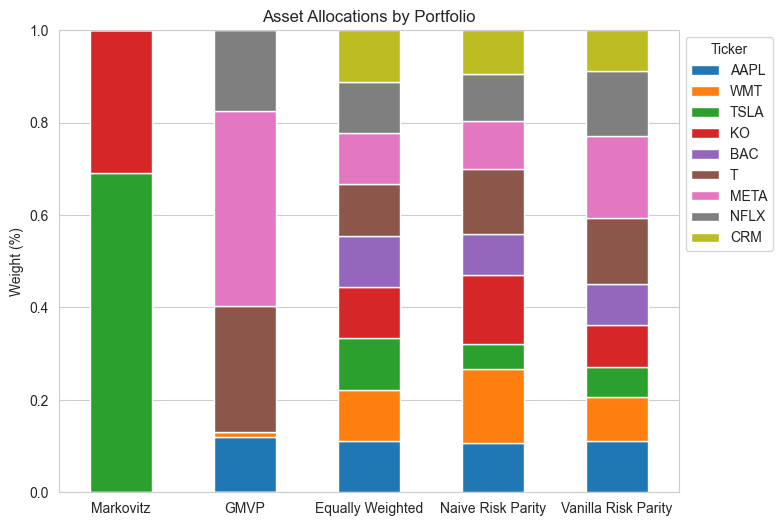

In [82]:
# • Compute and bar plot each asset’s allocations.
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
weights_df.T.plot(kind='bar', stacked=True, figsize=(8, 6))

plt.title('Asset Allocations by Portfolio')
plt.ylabel('Weight (%)')
plt.xticks(rotation=0) 
plt.legend(title='Ticker', bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

In [83]:
metrics_df = pd.DataFrame(index=weights_df.columns, columns=['Annual Return', 'Annual Std', 'Annual Sharpe Ratio'])
cumulative_returns_df = pd.DataFrame()

In [84]:
# • Compute the annualized returns, st dev and Sharpe ratio and plot the cumulative returns.
for portfolio_name, weights in weights_df.items():
    ann_ret = portfolio_return(weights, avg_returns)
    ann_std = portfolio_volatility(weights, cov_matrix)
    ann_sharpe = portfolio_sharpe(weights, avg_returns, cov_matrix, rf)
    metrics_df.loc[portfolio_name] = [ann_ret, ann_std, ann_sharpe]
    port_daily_returns = log_returns.dot(weights)
    cumulative_returns_df[portfolio_name] = (1 + port_daily_returns).cumprod() - 1

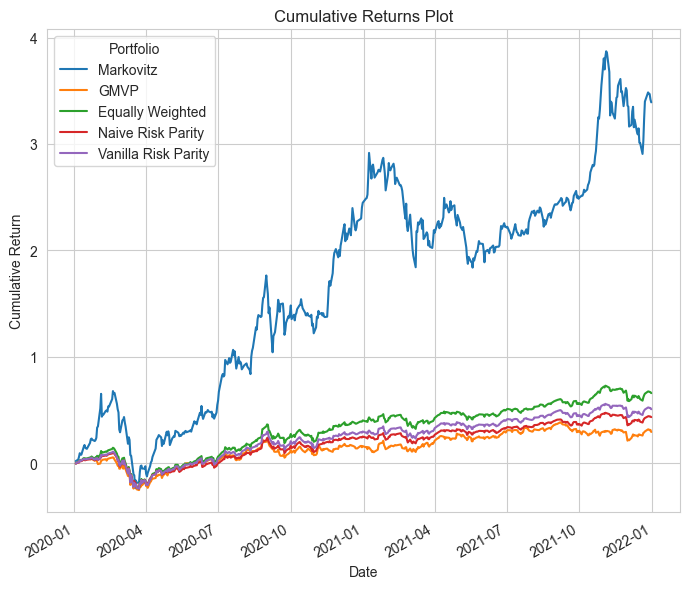

In [85]:
# Plot Cumulative Returns
plt.figure(figsize=(7, 6))
cumulative_returns_df.plot(figsize=(7, 6), ax=plt.gca())
plt.title('Cumulative Returns Plot')
plt.ylabel('Cumulative Return')
plt.xlabel('Date')
plt.legend(title='Portfolio')
plt.tight_layout()
plt.show()

In [72]:
# • Plot the drawdown.

In [73]:
drawdown_df = pd.DataFrame()
for portfolio_name, cum_ret in cumulative_returns_df.items():
    high_water_mark = (1 + cum_ret).cummax()
    drawdown = (high_water_mark - cum_ret)/high_water_mark
    drawdown_df[portfolio_name] = drawdown

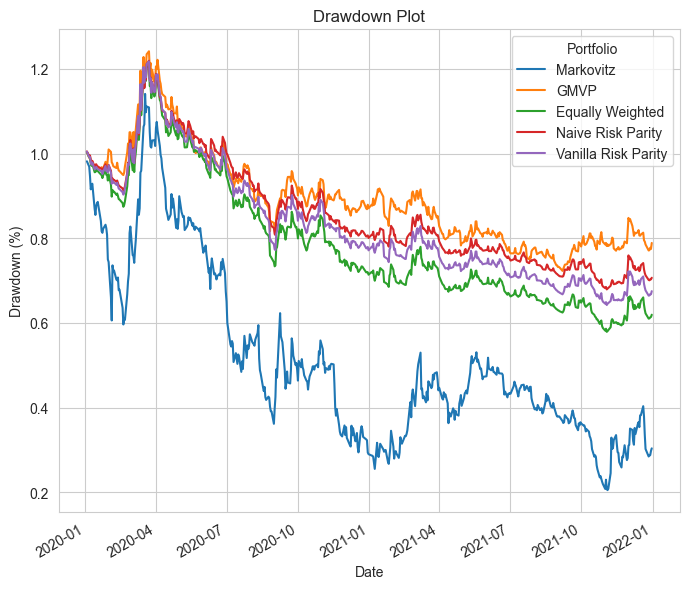

In [74]:
plt.figure(figsize=(7, 6))
drawdown_df.plot(figsize=(7, 6), ax=plt.gca())
plt.title('Drawdown Plot')
plt.ylabel('Drawdown (%)')
plt.xlabel('Date')
plt.legend(title='Portfolio')
plt.grid(True)
plt.tight_layout()
plt.show()

In [75]:
# • Compute and bar plot the risk contribution.

In [76]:
risk_contributions_df = pd.DataFrame()
for portfolio_name, weights in weights_df.items():
    total_risk_contribution, _ = daily_risk_contribution(weights, cov_matrix)
    risk_contributions_df[portfolio_name] = total_risk_contribution / np.sum(total_risk_contribution)

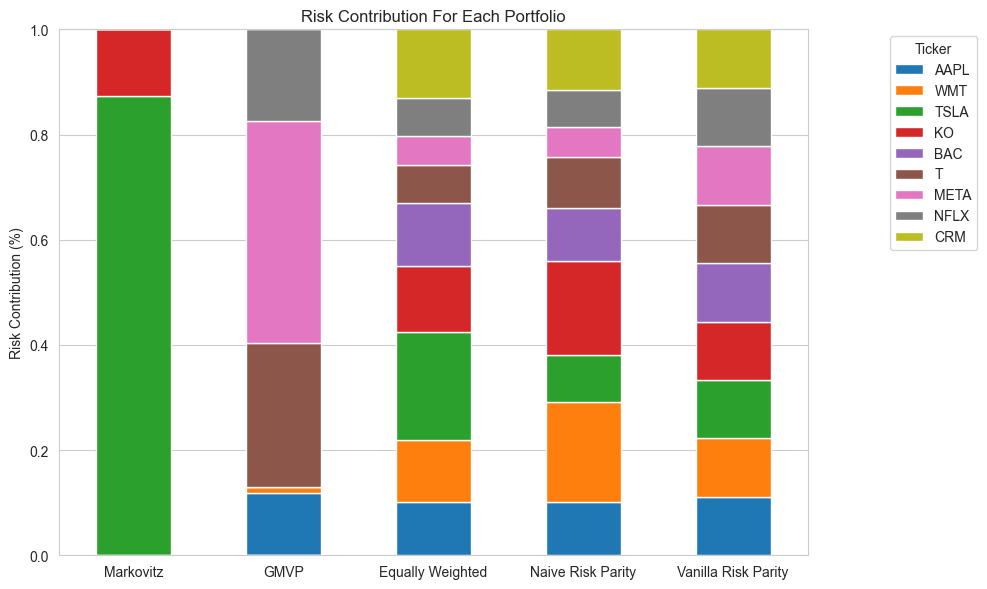

In [78]:
plt.figure(figsize=(8, 6))
risk_contributions_df.T.plot(kind='bar', stacked=True, figsize=(10, 6), ax=plt.gca())
plt.title('Risk Contribution For Each Portfolio')
plt.ylabel('Risk Contribution (%)')
plt.xticks(rotation=0)
plt.legend(title='Ticker', bbox_to_anchor=(1.1, 1), loc='upper left')
plt.tight_layout()
plt.show()